# 04 — Iris Multi-Class Classification: End-to-End Machine Learning

**Datheon | Machine Learning & Data Science Internship | Task 01**

This notebook builds, evaluates, compares, tunes, and saves multiple supervised classification models using the Iris dataset.

## Internship task requirements
- Stratified 80:20 train-test split
- Feature scaling using `StandardScaler`
- Logistic Regression and Decision Tree classifiers
- Accuracy, precision, recall, F1-score, classification reports, and confusion matrices

## Extended model benchmarking
In addition to the two required models, this notebook compares K-Nearest Neighbors, Support Vector Machine, Random Forest, Gaussian Naive Bayes, and Gradient Boosting. These are additional experiments, not replacements for the required models.

**Leakage prevention:** all preprocessing is fitted on training data through Scikit-learn pipelines. The test set is held back until final evaluation. Cross-validation and tuning use training data only.

**Important:** Iris has no date/time field. No artificial time-series analysis is created.


## 1. Environment and imports

In [1]:
# If needed, uncomment and run:
# %pip install pandas numpy matplotlib seaborn plotly scikit-learn joblib

import sys
import json
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

import joblib

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    GridSearchCV, learning_curve
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, auc,
    roc_auc_score
)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 6), "figure.dpi": 120})

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Python: 3.11.9
Pandas: 3.0.5
NumPy: 2.4.6


## 2. Locate project and load the cleaned dataset

Preferred input: `data/processed/iris_cleaned.csv` created by Notebook 02. If it is not present, this notebook falls back to the original `data/raw/iris.data` and performs basic schema/type validation without overwriting it.

In [2]:
current = Path.cwd()
PROJECT_ROOT = None

for p in [current, *current.parents]:
    if (p / "data").exists() and (p / "Jupyter-Notebook-Iris-Project").exists():
        PROJECT_ROOT = p
        break

if PROJECT_ROOT is None:
    # Fallback for notebook launched from inside its project folder
    for p in [current, *current.parents]:
        if (p / "data").exists():
            PROJECT_ROOT = p
            break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot locate project root. Expected data/ and Jupyter-Notebook-Iris-Project/."
    )

DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_FILE = DATA_DIR / "processed" / "iris_cleaned.csv"
RAW_FILE = DATA_DIR / "raw" / "iris.data"

OUTPUT_ROOT = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUT_ROOT / "figures"
INTERACTIVE_DIR = OUTPUT_ROOT / "interactive"
REPORTS_DIR = OUTPUT_ROOT / "reports"
MODELS_DIR = OUTPUT_ROOT / "models"

for folder in [FIGURES_DIR, INTERACTIVE_DIR, REPORTS_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

if PROCESSED_FILE.exists():
    df = pd.read_csv(PROCESSED_FILE)
    DATA_SOURCE_USED = str(PROCESSED_FILE)
elif RAW_FILE.exists():
    df = pd.read_csv(
        RAW_FILE, header=None,
        names=["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]
    )
    DATA_SOURCE_USED = str(RAW_FILE)
else:
    raise FileNotFoundError(
        "Neither data/processed/iris_cleaned.csv nor data/raw/iris.data was found."
    )

print("Project root:", PROJECT_ROOT)
print("Input data:", DATA_SOURCE_USED)
print("Shape:", df.shape)
display(df.head())

Project root: D:\Datheon-ML-Data-Science-Internship\Task-01-Iris-Classification
Input data: D:\Datheon-ML-Data-Science-Internship\Task-01-Iris-Classification\data\processed\iris_cleaned.csv
Shape: (150, 5)


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1000,3.5000,1.4000,0.2000,Iris-setosa
1,4.9000,3.0000,1.4000,0.2000,Iris-setosa
2,4.7000,3.2000,1.3000,0.2000,Iris-setosa
3,4.6000,3.1000,1.5000,0.2000,Iris-setosa
4,5.0000,3.6000,1.4000,0.2000,Iris-setosa


## 3. Validate dataset and define features / target

In [4]:
expected_columns = [
    "sepal_length_cm", "sepal_width_cm", "petal_length_cm", "petal_width_cm", "species"
]

# Normalize column labels in case the cleaned CSV contains harmless whitespace/case differences.
df.columns = [str(c).strip().lower() for c in df.columns]

missing_columns = sorted(set(expected_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")

df = df[expected_columns].copy()

feature_columns = expected_columns[:-1]
target_column = "species"

for col in feature_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df[target_column] = df[target_column].astype("string").str.strip()

print("Missing values:")
display(df.isna().sum().to_frame("missing_count"))

if df.isna().any().any():
    raise ValueError(
        "Missing values found. Resolve them in Notebook 02 and rerun this notebook. "
        "This modeling notebook will not silently drop records."
    )

if (df[feature_columns] <= 0).any().any():
    raise ValueError("Non-positive measurements found. Review the data in Notebook 02.")

print("Class distribution:")
display(df[target_column].value_counts().rename_axis("species").to_frame("count"))

X = df[feature_columns].copy()
y = df[target_column].copy()

print("Features:", feature_columns)
print("Classes:", sorted(y.unique()))
print("Total records:", len(df))

Missing values:


,missing_count
sepal_length_cm,0
sepal_width_cm,0
petal_length_cm,0
petal_width_cm,0
species,0


Class distribution:


,count
species,
Iris-setosa,50
Iris-versicolor,50
Iris-virginica,50


Features: ['sepal_length_cm', 'sepal_width_cm', 'petal_length_cm', 'petal_width_cm']
Classes: ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Total records: 150


## 4. Train-test split — stratified 80:20

In [5]:
RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

split_summary = pd.DataFrame({
    "Full dataset": y.value_counts(normalize=True).sort_index(),
    "Training set": y_train.value_counts(normalize=True).sort_index(),
    "Test set": y_test.value_counts(normalize=True).sort_index()
}).fillna(0)

display((split_summary * 100).round(2))
split_summary.to_csv(REPORTS_DIR / "train_test_class_distribution.csv")

Training records: 120
Testing records: 30


,Full dataset,Training set,Test set
species,,,
Iris-setosa,33.3300,33.3300,33.3300
Iris-versicolor,33.3300,33.3300,33.3300
Iris-virginica,33.3300,33.3300,33.3300


## 5. Define baseline classification models

Logistic Regression and Decision Tree are the task-required models. The other five models are additional comparative baselines. Scaling is included for distance- and margin-based models; tree ensembles and Naive Bayes are run without scaling.

In [6]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline([
        ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE))
    ]),
    "K-Nearest Neighbors": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("classifier", RandomForestClassifier(
            n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1
        ))
    ]),
    "Gaussian Naive Bayes": Pipeline([
        ("classifier", GaussianNB())
    ]),
    "Gradient Boosting": Pipeline([
        ("classifier", GradientBoostingClassifier(random_state=RANDOM_STATE))
    ])
}

print("Models prepared:")
for i, name in enumerate(models, start=1):
    print(f"{i}. {name}")

Models prepared:
1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors
4. Support Vector Machine
5. Random Forest
6. Gaussian Naive Bayes
7. Gradient Boosting


## 6. Cross-validation on training data

Use stratified 5-fold cross-validation. This estimates performance using training data only; the held-out test set remains untouched.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro"
}

cv_rows = []
for name, estimator in models.items():
    scores = cross_validate(
        estimator, X_train, y_train,
        cv=cv, scoring=scoring, n_jobs=-1,
        return_train_score=False
    )
    cv_rows.append({
        "Model": name,
        "CV Accuracy Mean": scores["test_accuracy"].mean(),
        "CV Accuracy Std": scores["test_accuracy"].std(),
        "CV Precision Macro": scores["test_precision_macro"].mean(),
        "CV Recall Macro": scores["test_recall_macro"].mean(),
        "CV F1 Macro": scores["test_f1_macro"].mean()
    })

cv_results = pd.DataFrame(cv_rows).sort_values("CV F1 Macro", ascending=False)
display(cv_results.style.format(precision=4))
cv_results.to_csv(REPORTS_DIR / "cross_validation_results.csv", index=False)

,Model,CV Accuracy Mean,CV Accuracy Std,CV Precision Macro,CV Recall Macro,CV F1 Macro
3,Support Vector Machine,0.9667,0.0167,0.9704,0.9667,0.9665
2,K-Nearest Neighbors,0.9583,0.0264,0.9644,0.9583,0.9580
0,Logistic Regression,0.9583,0.0264,0.9644,0.9583,0.9580
1,Decision Tree,0.9500,0.0167,0.9570,0.9500,0.9496
5,Gaussian Naive Bayes,0.9500,0.0167,0.9570,0.9500,0.9496
4,Random Forest,0.9500,0.0312,0.9585,0.9500,0.9494
6,Gradient Boosting,0.9500,0.0312,0.9585,0.9500,0.9494


## 7. Fit baseline models and evaluate on held-out test set

In [8]:
fitted_models = {}
baseline_rows = []
baseline_predictions = {}

for name, estimator in models.items():
    estimator.fit(X_train, y_train)
    predictions = estimator.predict(X_test)

    fitted_models[name] = estimator
    baseline_predictions[name] = predictions

    baseline_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision Macro": precision_score(y_test, predictions, average="macro", zero_division=0),
        "Recall Macro": recall_score(y_test, predictions, average="macro", zero_division=0),
        "F1 Macro": f1_score(y_test, predictions, average="macro", zero_division=0),
        "F1 Weighted": f1_score(y_test, predictions, average="weighted", zero_division=0)
    })

baseline_results = pd.DataFrame(baseline_rows).sort_values("F1 Macro", ascending=False)
display(baseline_results.style.format(precision=4))
baseline_results.to_csv(REPORTS_DIR / "baseline_model_comparison.csv", index=False)

,Model,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
6,Gradient Boosting,0.9667,0.9697,0.9667,0.9666,0.9666
5,Gaussian Naive Bayes,0.9667,0.9697,0.9667,0.9666,0.9666
3,Support Vector Machine,0.9667,0.9697,0.9667,0.9666,0.9666
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333,0.9333
2,K-Nearest Neighbors,0.9333,0.9444,0.9333,0.9327,0.9327
4,Random Forest,0.9000,0.9024,0.9000,0.8997,0.8997


## 8. Model comparison visualizations

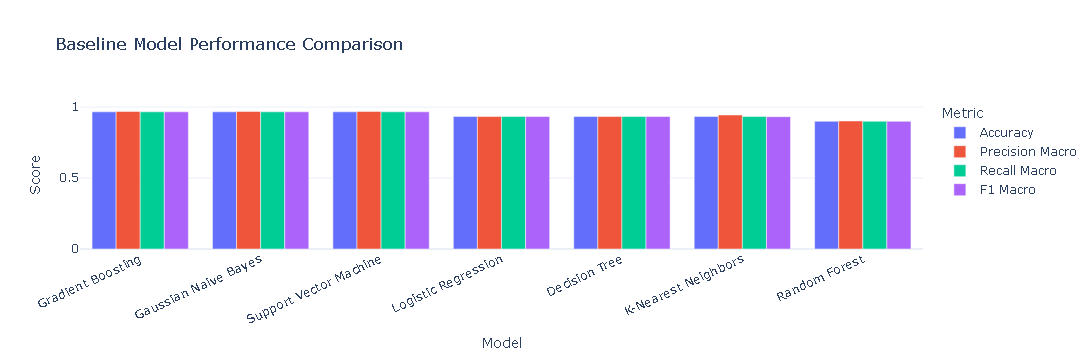

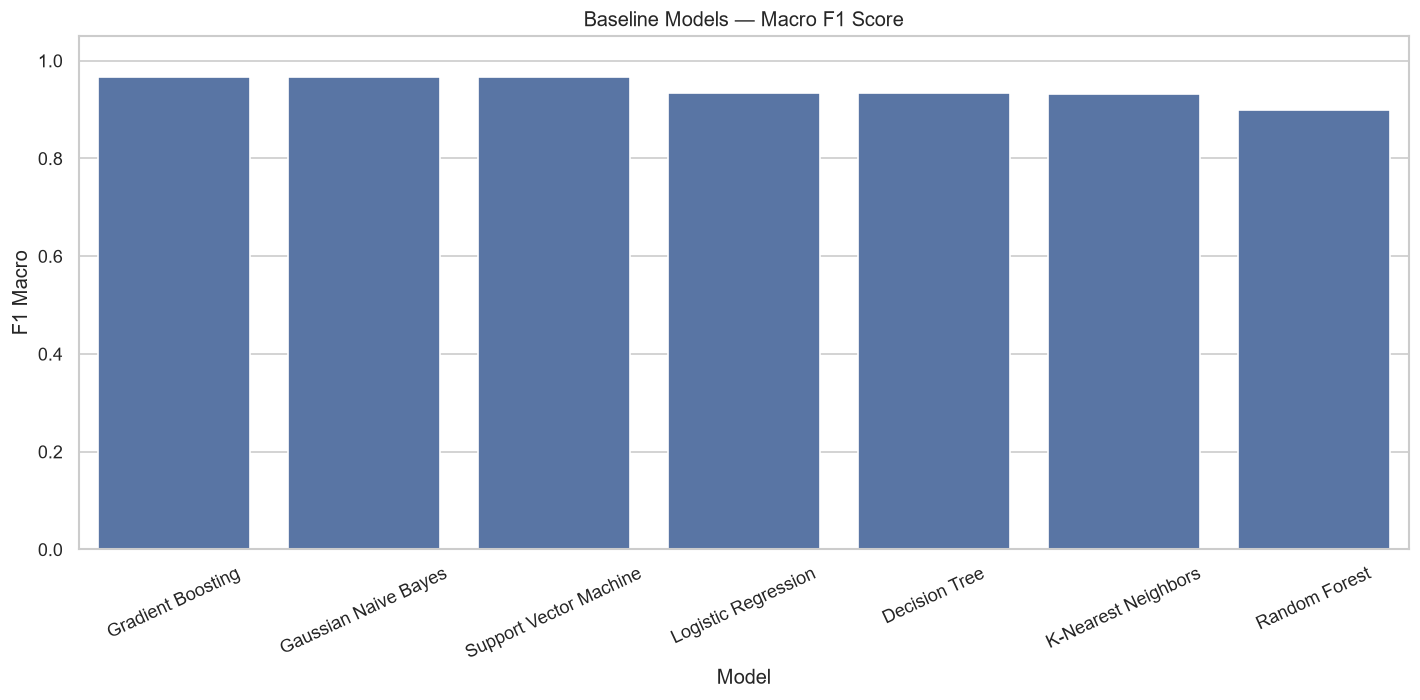

In [9]:
metric_long = baseline_results.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision Macro", "Recall Macro", "F1 Macro"],
    var_name="Metric",
    value_name="Score"
)

fig = px.bar(
    metric_long, x="Model", y="Score", color="Metric", barmode="group",
    title="Baseline Model Performance Comparison",
    range_y=[0, 1.05], template="plotly_white"
)
fig.update_layout(xaxis_tickangle=-25)
fig.write_html(INTERACTIVE_DIR / "model_performance_comparison.html")
fig.show()

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=baseline_results, x="Model", y="F1 Macro", ax=ax)
ax.set_ylim(0, 1.05)
ax.set_title("Baseline Models — Macro F1 Score")
ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "model_f1_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## 9. Classification reports for required models

In [10]:
required_models = ["Logistic Regression", "Decision Tree"]

for name in required_models:
    print("\n" + "=" * 70)
    print(name.upper())
    print("=" * 70)
    report = classification_report(
        y_test, baseline_predictions[name],
        output_dict=True, zero_division=0
    )
    print(classification_report(
        y_test, baseline_predictions[name], zero_division=0
    ))
    pd.DataFrame(report).T.to_csv(
        REPORTS_DIR / f"{name.lower().replace(' ', '_')}_classification_report.csv"
    )


LOGISTIC REGRESSION
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30


DECISION TREE
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



## 10. Confusion matrices — all baseline models

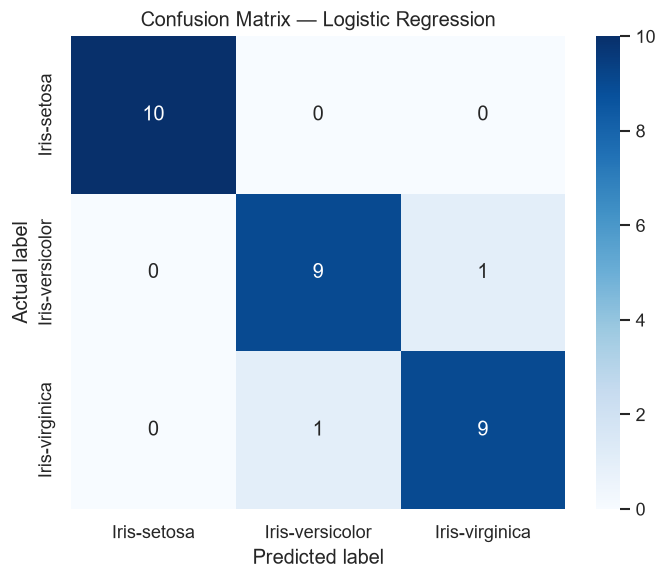

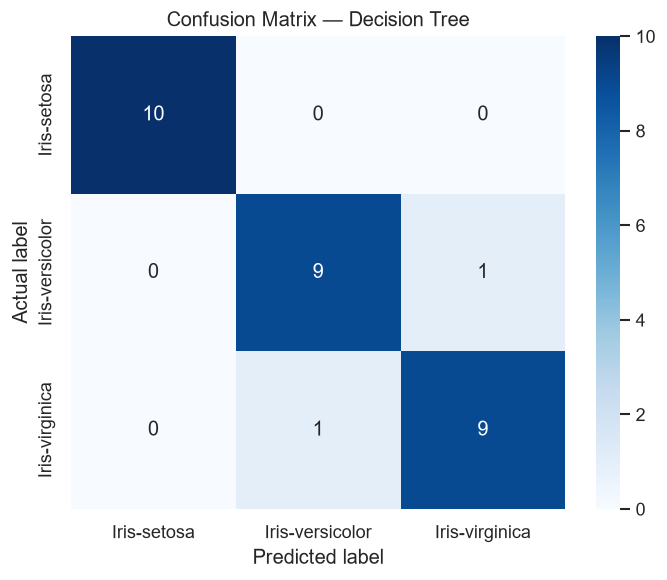

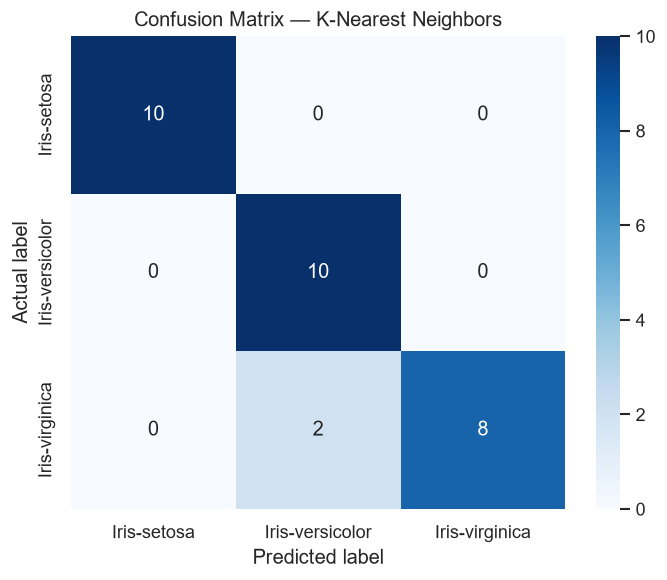

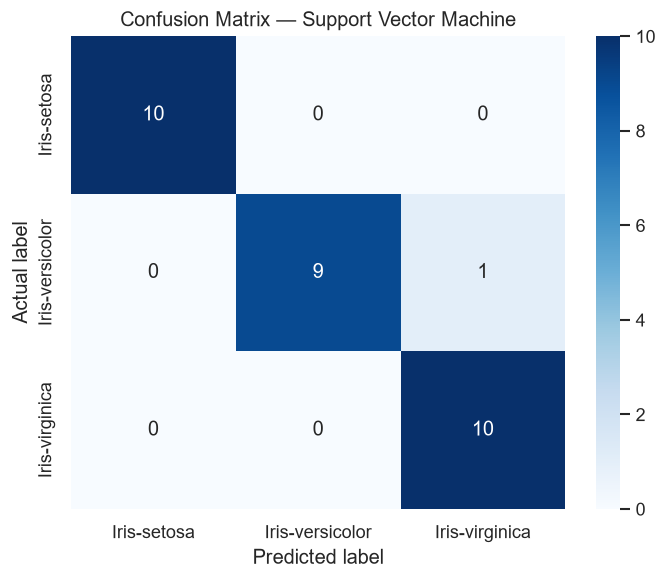

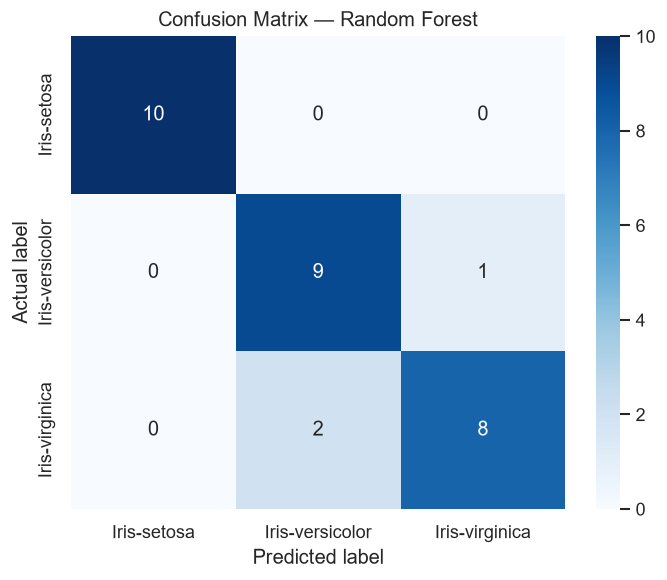

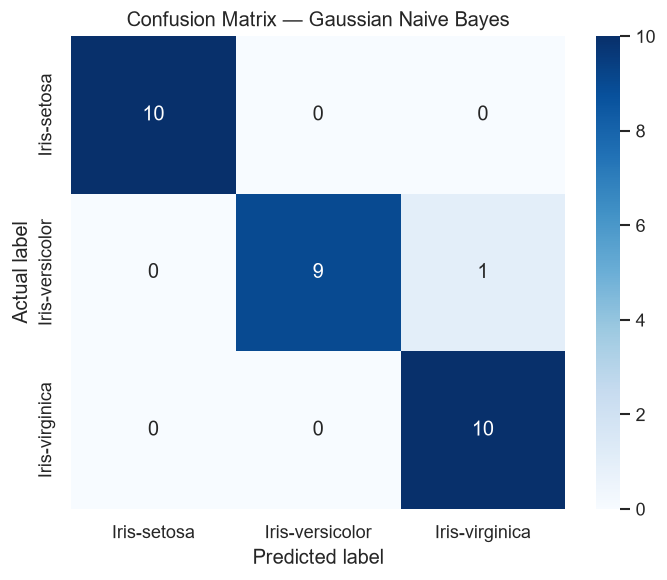

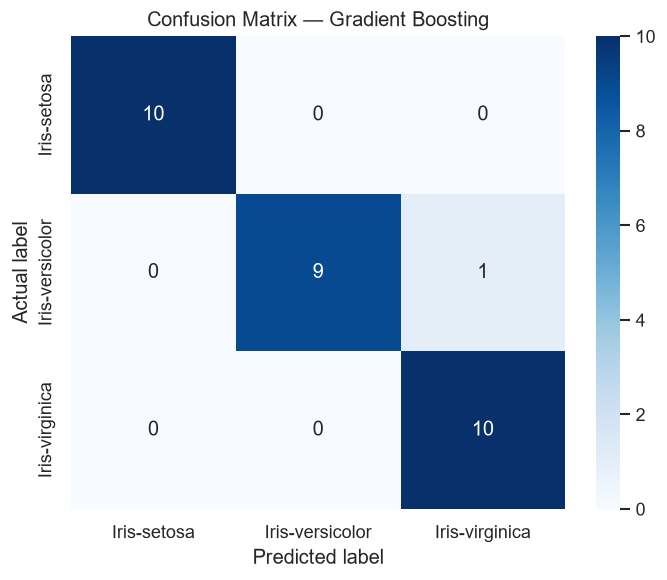

In [11]:
class_labels = sorted(y.unique())

for name, predictions in baseline_predictions.items():
    cm = confusion_matrix(y_test, predictions, labels=class_labels)

    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=class_labels, yticklabels=class_labels, ax=ax
    )
    ax.set_title(f"Confusion Matrix — {name}")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
    fig.tight_layout()
    safe_name = name.lower().replace(" ", "_")
    fig.savefig(FIGURES_DIR / f"confusion_matrix_{safe_name}.png",
                dpi=300, bbox_inches="tight")
    plt.show()

    pd.DataFrame(
        cm, index=class_labels, columns=class_labels
    ).to_csv(REPORTS_DIR / f"confusion_matrix_{safe_name}.csv")

## 11. Hyperparameter tuning — required models and selected extensions

Grid search is performed using only the training set and stratified cross-validation. The final test set is not used to choose hyperparameters.

In [12]:
param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10, 100],
        "classifier__solver": ["lbfgs"],
        "classifier__class_weight": [None, "balanced"]
    },
    "Decision Tree": {
        "classifier__criterion": ["gini", "entropy", "log_loss"],
        "classifier__max_depth": [None, 2, 3, 4, 5],
        "classifier__min_samples_split": [2, 4, 6],
        "classifier__min_samples_leaf": [1, 2, 3]
    },
    "Support Vector Machine": {
        "classifier__C": [0.1, 1, 10, 100],
        "classifier__gamma": ["scale", "auto"],
        "classifier__kernel": ["rbf", "linear"]
    },
    "Random Forest": {
        "classifier__n_estimators": [100, 300],
        "classifier__max_depth": [None, 3, 5, 8],
        "classifier__min_samples_leaf": [1, 2]
    }
}

tuned_models = {}
tuning_rows = []

for name, grid in param_grids.items():
    print("Tuning:", name)
    search = GridSearchCV(
        estimator=models[name],
        param_grid=grid,
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        refit=True
    )
    search.fit(X_train, y_train)
    tuned_models[name] = search.best_estimator_
    tuning_rows.append({
        "Model": name,
        "Best CV Macro F1": search.best_score_,
        "Best Parameters": json.dumps(search.best_params_, default=str)
    })

tuning_results = pd.DataFrame(tuning_rows).sort_values(
    "Best CV Macro F1", ascending=False
)
display(tuning_results)
tuning_results.to_csv(REPORTS_DIR / "hyperparameter_tuning_results.csv", index=False)

Tuning: Logistic Regression
Tuning: Decision Tree
Tuning: Support Vector Machine
Tuning: Random Forest


,Model,Best CV Macro F1,Best Parameters
2,Support Vector Machine,0.9749,"{""classifier__C"": 0.1, ""classifier__gamma"": ""s..."
0,Logistic Regression,0.9663,"{""classifier__C"": 10, ""classifier__class_weigh..."
1,Decision Tree,0.9663,"{""classifier__criterion"": ""gini"", ""classifier_..."
3,Random Forest,0.9663,"{""classifier__max_depth"": null, ""classifier__m..."


## 12. Evaluate tuned models on the test set

In [13]:
tuned_rows = []
tuned_predictions = {}

for name, estimator in tuned_models.items():
    predictions = estimator.predict(X_test)
    tuned_predictions[name] = predictions

    tuned_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision Macro": precision_score(y_test, predictions, average="macro", zero_division=0),
        "Recall Macro": recall_score(y_test, predictions, average="macro", zero_division=0),
        "F1 Macro": f1_score(y_test, predictions, average="macro", zero_division=0),
        "F1 Weighted": f1_score(y_test, predictions, average="weighted", zero_division=0)
    })

tuned_results = pd.DataFrame(tuned_rows).sort_values("F1 Macro", ascending=False)
display(tuned_results.style.format(precision=4))
tuned_results.to_csv(REPORTS_DIR / "tuned_model_test_results.csv", index=False)

,Model,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
0,Logistic Regression,1.0000,1.0000,1.0000,1.0000,1.0000
1,Decision Tree,0.9667,0.9697,0.9667,0.9666,0.9666
3,Random Forest,0.9667,0.9697,0.9667,0.9666,0.9666
2,Support Vector Machine,0.9333,0.9333,0.9333,0.9333,0.9333


## 13. Baseline vs tuned comparison

,Model,Version,Accuracy,Macro F1
0,Gradient Boosting,Baseline,0.9667,0.9666
1,Gaussian Naive Bayes,Baseline,0.9667,0.9666
2,Support Vector Machine,Baseline,0.9667,0.9666
3,Logistic Regression,Baseline,0.9333,0.9333
4,Decision Tree,Baseline,0.9333,0.9333
5,K-Nearest Neighbors,Baseline,0.9333,0.9327
6,Random Forest,Baseline,0.9000,0.8997
7,Logistic Regression,Tuned,1.0000,1.0000
8,Decision Tree,Tuned,0.9667,0.9666
9,Random Forest,Tuned,0.9667,0.9666


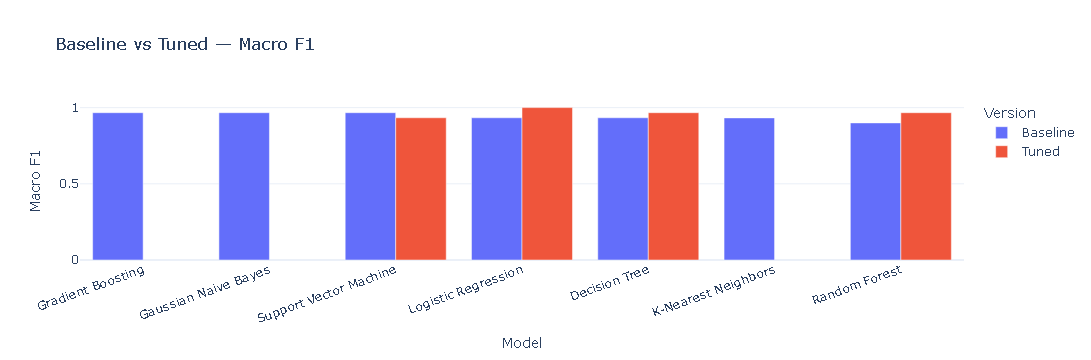

In [14]:
comparison_parts = []
for _, row in baseline_results.iterrows():
    comparison_parts.append({
        "Model": row["Model"], "Version": "Baseline", "Accuracy": row["Accuracy"],
        "Macro F1": row["F1 Macro"]
    })
for _, row in tuned_results.iterrows():
    comparison_parts.append({
        "Model": row["Model"], "Version": "Tuned", "Accuracy": row["Accuracy"],
        "Macro F1": row["F1 Macro"]
    })

tuning_comparison = pd.DataFrame(comparison_parts)
display(tuning_comparison)
tuning_comparison.to_csv(REPORTS_DIR / "baseline_vs_tuned.csv", index=False)

fig = px.bar(
    tuning_comparison, x="Model", y="Macro F1", color="Version",
    barmode="group", range_y=[0, 1.05],
    title="Baseline vs Tuned — Macro F1",
    template="plotly_white"
)
fig.update_layout(xaxis_tickangle=-20)
fig.write_html(INTERACTIVE_DIR / "baseline_vs_tuned.html")
fig.show()

## 14. Multiclass ROC-AUC and ROC curves

One-vs-rest ROC curves are calculated for models that provide class probabilities. Macro ROC-AUC summarizes class-level discrimination; interpret it alongside the classification report and confusion matrix.

,Model,Multiclass ROC-AUC OVR Macro
0,Logistic Regression,1.0000
2,K-Nearest Neighbors,0.9933
3,Support Vector Machine,0.9900
5,Gaussian Naive Bayes,0.9900
4,Random Forest,0.9867
6,Gradient Boosting,0.9833
1,Decision Tree,0.9717


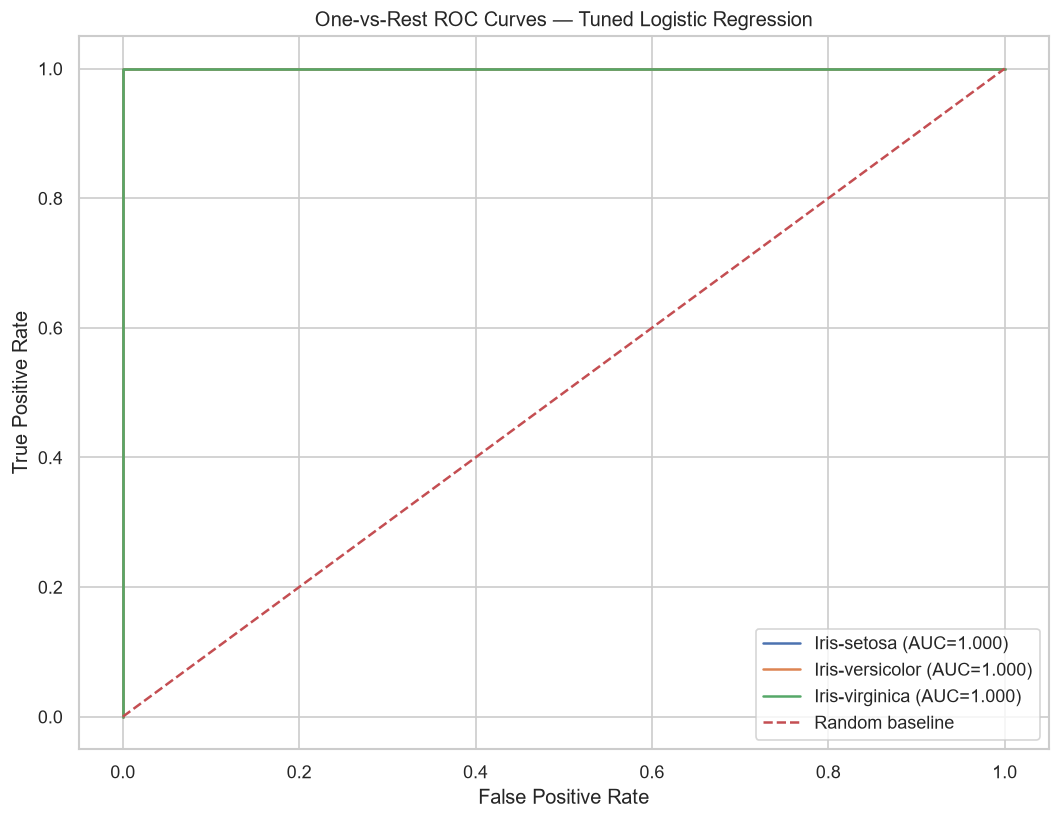

In [15]:
roc_rows = []
plt.figure(figsize=(9, 7))

for name, estimator in {**fitted_models, **tuned_models}.items():
    if not hasattr(estimator, "predict_proba"):
        continue
    probabilities = estimator.predict_proba(X_test)
    try:
        auc_macro = roc_auc_score(
            y_test, probabilities,
            multi_class="ovr", average="macro",
            labels=estimator.classes_
        )
        roc_rows.append({"Model": name, "Multiclass ROC-AUC OVR Macro": auc_macro})
    except ValueError:
        continue

roc_results = pd.DataFrame(roc_rows).drop_duplicates("Model")
display(roc_results.sort_values("Multiclass ROC-AUC OVR Macro", ascending=False))
roc_results.to_csv(REPORTS_DIR / "multiclass_roc_auc.csv", index=False)

# Plot one-vs-rest curves for the tuned Logistic Regression model, if available.
roc_model = tuned_models.get("Logistic Regression", fitted_models["Logistic Regression"])
y_test_bin = label_binarize(y_test, classes=list(roc_model.classes_))
y_score = roc_model.predict_proba(X_test)

for i, class_name in enumerate(roc_model.classes_):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    plt.plot(fpr, tpr, label=f"{class_name} (AUC={auc(fpr, tpr):.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("One-vs-Rest ROC Curves — Tuned Logistic Regression")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "multiclass_roc_curves.png", dpi=300, bbox_inches="tight")
plt.show()

## 15. Decision Tree visualization

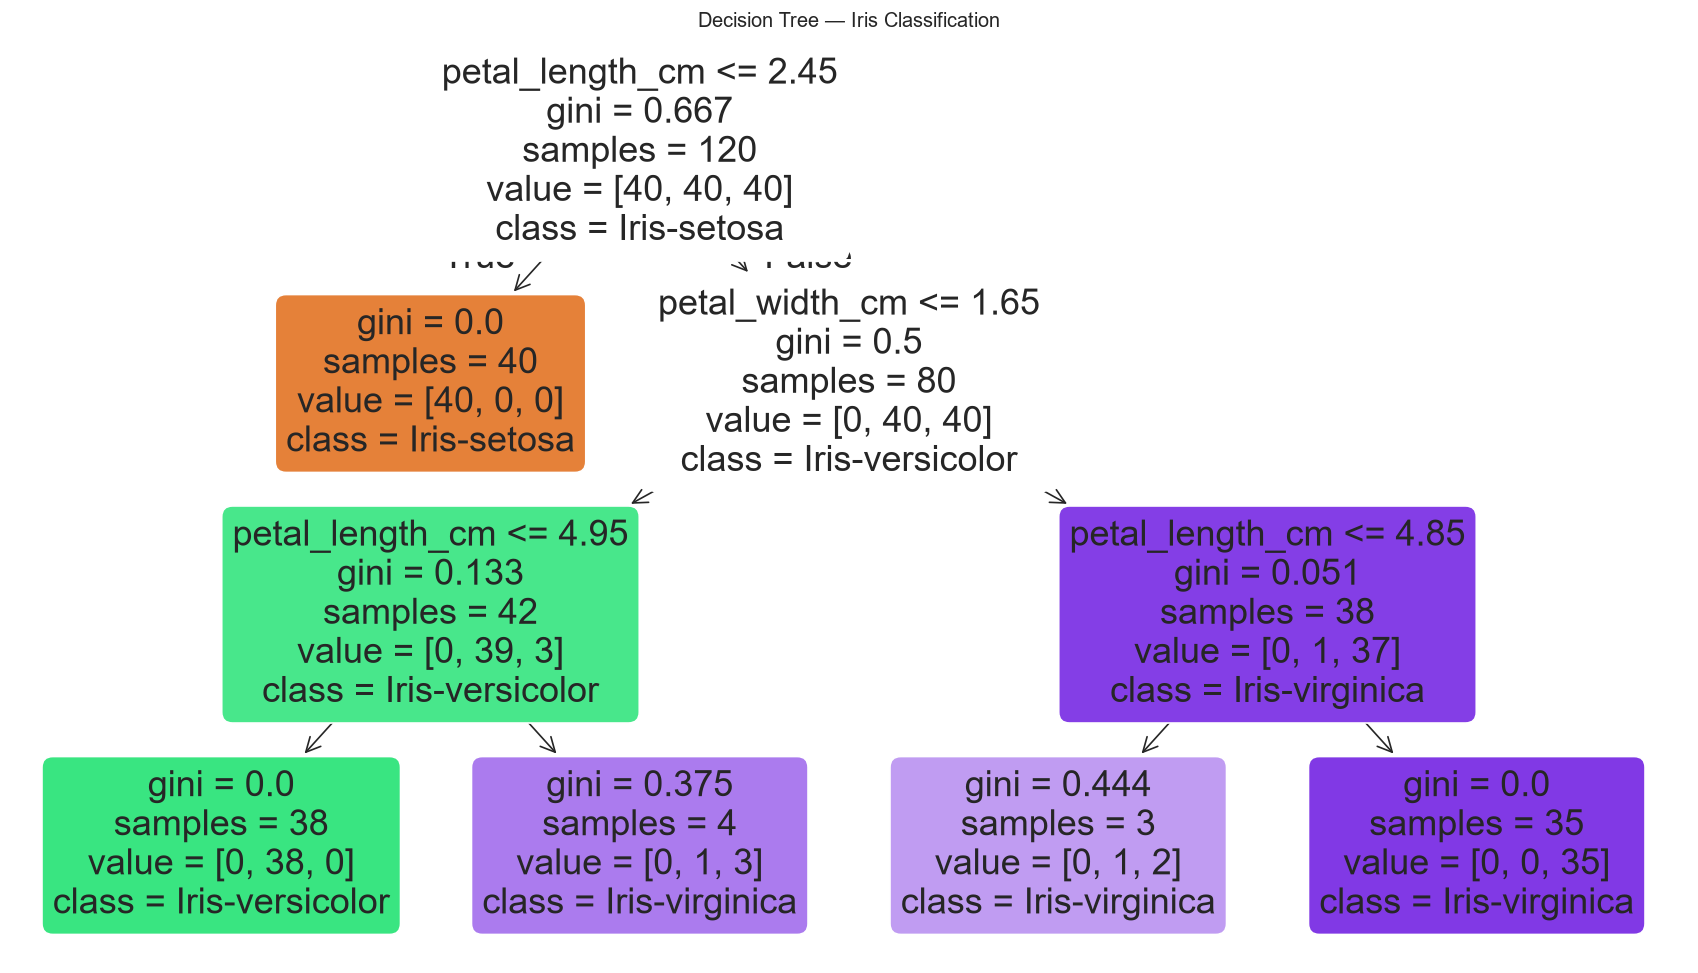

In [16]:
tree_pipeline = tuned_models.get("Decision Tree", fitted_models["Decision Tree"])
tree_model = tree_pipeline.named_steps["classifier"]

fig, ax = plt.subplots(figsize=(18, 10))
plot_tree(
    tree_model,
    feature_names=feature_columns,
    class_names=[str(c) for c in tree_model.classes_],
    filled=True,
    rounded=True,
    proportion=False,
    impurity=True,
    ax=ax
)
ax.set_title("Decision Tree — Iris Classification")
fig.savefig(FIGURES_DIR / "decision_tree_visualization.png",
            dpi=300, bbox_inches="tight")
plt.show()

## 16. Feature importance — tree-based model

,Feature,Importance
3,petal_width_cm,0.4437
2,petal_length_cm,0.4374
0,sepal_length_cm,0.1106
1,sepal_width_cm,0.0082


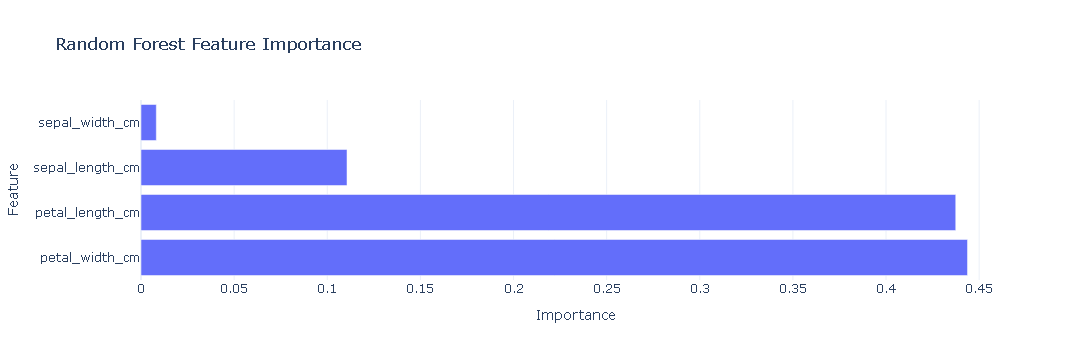

In [17]:
rf_pipeline = tuned_models.get("Random Forest", fitted_models["Random Forest"])
rf_model = rf_pipeline.named_steps["classifier"]

importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance)
importance.to_csv(REPORTS_DIR / "random_forest_feature_importance.csv", index=False)

fig = px.bar(
    importance, x="Importance", y="Feature", orientation="h",
    title="Random Forest Feature Importance",
    template="plotly_white"
)
fig.write_html(INTERACTIVE_DIR / "feature_importance.html")
fig.show()

## 17. Permutation importance — held-out test set

Permutation importance measures how much a fitted model's test score decreases when one feature is shuffled. It is a model- and dataset-dependent diagnostic, not a causal explanation.

,Feature,Importance Mean,Importance Std
3,petal_width_cm,0.2794,0.0734
2,petal_length_cm,0.2744,0.0692
1,sepal_width_cm,0.1102,0.0415
0,sepal_length_cm,0.0873,0.0311


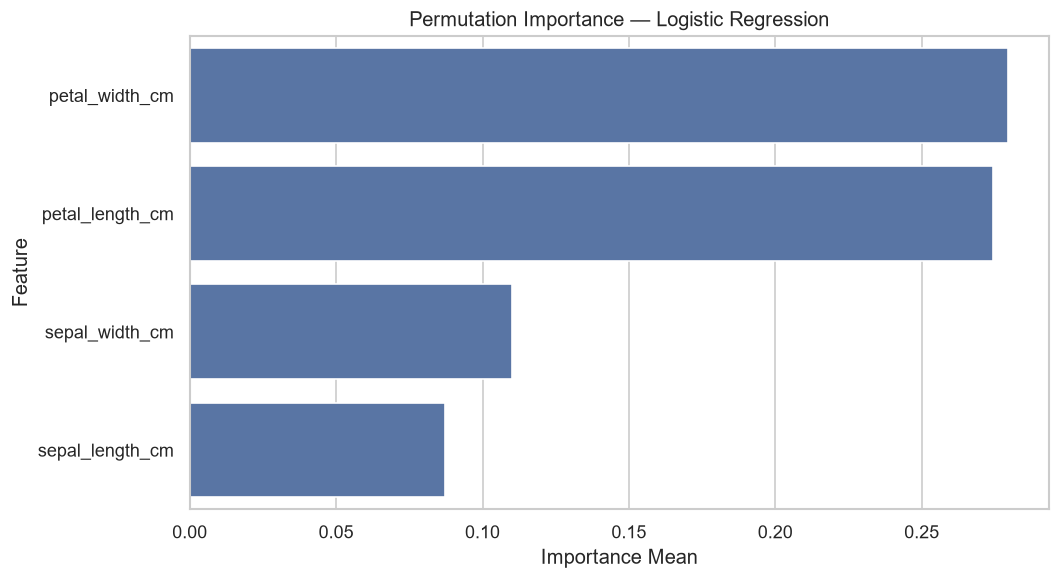

In [18]:
best_tuned_name = tuned_results.iloc[0]["Model"]
best_tuned_model = tuned_models[best_tuned_name]

perm = permutation_importance(
    best_tuned_model, X_test, y_test,
    n_repeats=30, random_state=RANDOM_STATE,
    scoring="f1_macro", n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance Mean": perm.importances_mean,
    "Importance Std": perm.importances_std
}).sort_values("Importance Mean", ascending=False)

display(permutation_df)
permutation_df.to_csv(REPORTS_DIR / "permutation_importance.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=permutation_df, x="Importance Mean", y="Feature", ax=ax)
ax.set_title(f"Permutation Importance — {best_tuned_name}")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "permutation_importance.png", dpi=300, bbox_inches="tight")
plt.show()

## 18. Learning curve — selected best tuned model

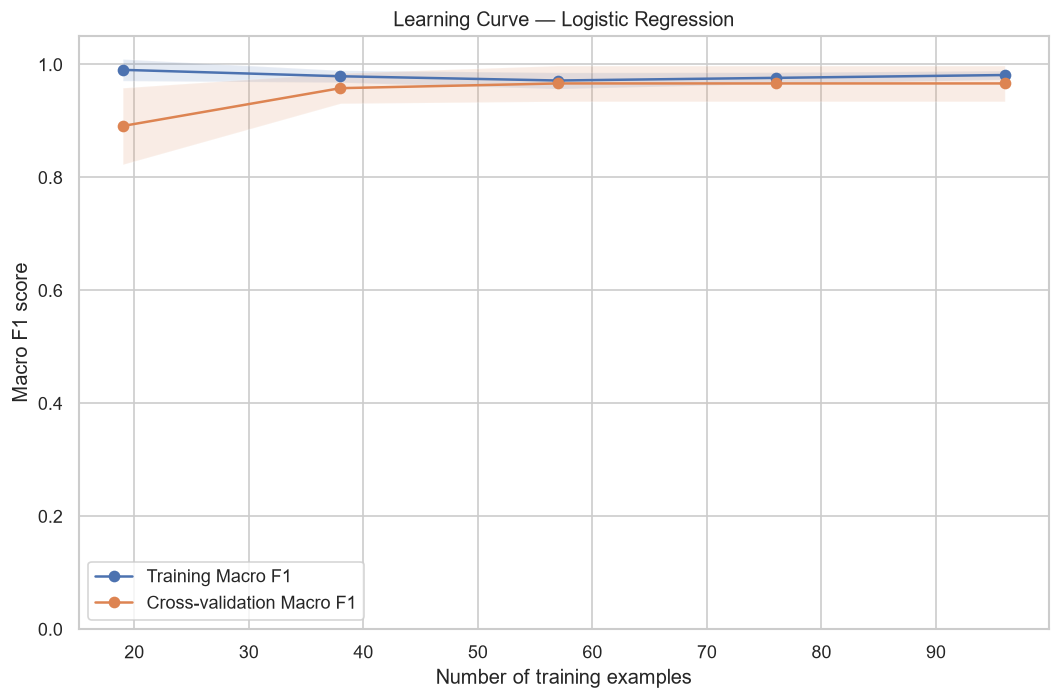

In [19]:
train_sizes, train_scores, validation_scores = learning_curve(
    best_tuned_model, X_train, y_train,
    cv=cv, scoring="f1_macro",
    train_sizes=np.linspace(0.2, 1.0, 5),
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
valid_mean = validation_scores.mean(axis=1)
valid_std = validation_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(train_sizes, train_mean, marker="o", label="Training Macro F1")
ax.plot(train_sizes, valid_mean, marker="o", label="Cross-validation Macro F1")
ax.fill_between(train_sizes, train_mean-train_std, train_mean+train_std, alpha=0.15)
ax.fill_between(train_sizes, valid_mean-valid_std, valid_mean+valid_std, alpha=0.15)
ax.set(
    title=f"Learning Curve — {best_tuned_name}",
    xlabel="Number of training examples",
    ylabel="Macro F1 score",
    ylim=(0, 1.05)
)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "learning_curve.png", dpi=300, bbox_inches="tight")
plt.show()

## 19. Select final model and save artifacts

The selection rule below chooses the tuned candidate with the highest cross-validation Macro F1, not the highest test score. This avoids selecting a model based on repeated test-set comparisons. The test metrics are then reported for the selected model.

In [20]:
best_tuned_row = tuning_results.sort_values("Best CV Macro F1", ascending=False).iloc[0]
FINAL_MODEL_NAME = best_tuned_row["Model"]
FINAL_MODEL = tuned_models[FINAL_MODEL_NAME]

final_predictions = FINAL_MODEL.predict(X_test)

final_metrics = {
    "selected_model": FINAL_MODEL_NAME,
    "selection_basis": "Highest stratified 5-fold training CV Macro F1 among tuned candidates",
    "test_accuracy": float(accuracy_score(y_test, final_predictions)),
    "test_precision_macro": float(precision_score(y_test, final_predictions, average="macro", zero_division=0)),
    "test_recall_macro": float(recall_score(y_test, final_predictions, average="macro", zero_division=0)),
    "test_f1_macro": float(f1_score(y_test, final_predictions, average="macro", zero_division=0)),
    "test_f1_weighted": float(f1_score(y_test, final_predictions, average="weighted", zero_division=0)),
    "feature_columns": feature_columns,
    "classes": [str(c) for c in FINAL_MODEL.classes_],
    "random_state": RANDOM_STATE,
    "test_size": 0.20
}

joblib.dump(FINAL_MODEL, MODELS_DIR / "iris_best_classifier.joblib")
with open(REPORTS_DIR / "final_model_metrics.json", "w", encoding="utf-8") as f:
    json.dump(final_metrics, f, indent=4)

with open(REPORTS_DIR / "final_classification_report.json", "w", encoding="utf-8") as f:
    json.dump(
        classification_report(y_test, final_predictions, output_dict=True, zero_division=0),
        f, indent=4
    )

print("Selected model:", FINAL_MODEL_NAME)
print(json.dumps(final_metrics, indent=4))
print("Saved model:", MODELS_DIR / "iris_best_classifier.joblib")

Selected model: Support Vector Machine
{
    "selected_model": "Support Vector Machine",
    "selection_basis": "Highest stratified 5-fold training CV Macro F1 among tuned candidates",
    "test_accuracy": 0.9333333333333333,
    "test_precision_macro": 0.9333333333333332,
    "test_recall_macro": 0.9333333333333332,
    "test_f1_macro": 0.9333333333333332,
    "test_f1_weighted": 0.9333333333333333,
    "feature_columns": [
        "sepal_length_cm",
        "sepal_width_cm",
        "petal_length_cm",
        "petal_width_cm"
    ],
    "classes": [
        "Iris-setosa",
        "Iris-versicolor",
        "Iris-virginica"
    ],
    "random_state": 42,
    "test_size": 0.2
}
Saved model: D:\Datheon-ML-Data-Science-Internship\Task-01-Iris-Classification\outputs\models\iris_best_classifier.joblib


## 20. Save all trained model pipelines

In [21]:
# Save baseline and tuned estimators for reproducibility.
for name, estimator in fitted_models.items():
    filename = name.lower().replace(" ", "_") + "_baseline.joblib"
    joblib.dump(estimator, MODELS_DIR / filename)

for name, estimator in tuned_models.items():
    filename = name.lower().replace(" ", "_") + "_tuned.joblib"
    joblib.dump(estimator, MODELS_DIR / filename)

print("Saved baseline and tuned model pipelines to:", MODELS_DIR)

Saved baseline and tuned model pipelines to: D:\Datheon-ML-Data-Science-Internship\Task-01-Iris-Classification\outputs\models


## 21. Prediction demonstration

In [22]:
# Demonstrate inference using one test observation.
sample = X_test.iloc[[0]]
actual_label = y_test.iloc[0]
predicted_label = FINAL_MODEL.predict(sample)[0]

print("Input features:")
display(sample)
print("Actual species:", actual_label)
print("Predicted species:", predicted_label)

if hasattr(FINAL_MODEL, "predict_proba"):
    probabilities = FINAL_MODEL.predict_proba(sample)[0]
    probability_table = pd.DataFrame({
        "Species": FINAL_MODEL.classes_,
        "Predicted Probability": probabilities
    }).sort_values("Predicted Probability", ascending=False)
    display(probability_table)

Input features:


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
38,4.4000,3.0000,1.3000,0.2000


Actual species: Iris-setosa
Predicted species: Iris-setosa


,Species,Predicted Probability
0,Iris-setosa,0.9732
1,Iris-versicolor,0.0181
2,Iris-virginica,0.0086


## 22. Final audit and reproducibility summary

In [23]:
print("=" * 72)
print("IRIS CLASSIFICATION — FINAL PROJECT AUDIT")
print("=" * 72)
print("Input dataset:", DATA_SOURCE_USED)
print("Rows:", len(df))
print("Features:", feature_columns)
print("Classes:", sorted(y.unique()))
print("Train/test:", len(X_train), "/", len(X_test))
print("Baseline models:", len(fitted_models))
print("Tuned models:", len(tuned_models))
print("Selected model:", FINAL_MODEL_NAME)
print("Test Macro F1:", round(final_metrics["test_f1_macro"], 4))

for label, folder in [
    ("Figures", FIGURES_DIR),
    ("Interactive HTML", INTERACTIVE_DIR),
    ("Reports", REPORTS_DIR),
    ("Models", MODELS_DIR)
]:
    files = [p for p in folder.iterdir() if p.is_file()]
    print(f"\n{label}: {len(files)} files")
    for path in sorted(files):
        print(" -", path.name)

print("\nNo .ipynb files are created by this notebook.")
print("The raw dataset is not modified.")
print("Modeling workflow completed.")

IRIS CLASSIFICATION — FINAL PROJECT AUDIT
Input dataset: D:\Datheon-ML-Data-Science-Internship\Task-01-Iris-Classification\data\processed\iris_cleaned.csv
Rows: 150
Features: ['sepal_length_cm', 'sepal_width_cm', 'petal_length_cm', 'petal_width_cm']
Classes: ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Train/test: 120 / 30
Baseline models: 7
Tuned models: 4
Selected model: Support Vector Machine
Test Macro F1: 0.9333

Figures: 19 files
 - boxplots.png
 - confusion_matrix_decision_tree.png
 - confusion_matrix_gaussian_naive_bayes.png
 - confusion_matrix_gradient_boosting.png
 - confusion_matrix_k-nearest_neighbors.png
 - confusion_matrix_logistic_regression.png
 - confusion_matrix_random_forest.png
 - confusion_matrix_support_vector_machine.png
 - correlation_heatmap.png
 - decision_tree_visualization.png
 - feature_distributions.png
 - learning_curve.png
 - model_f1_comparison.png
 - multiclass_roc_curves.png
 - pairplot.png
 - permutation_importance.png
 - species_distribution

## 23. Interpretation and limitations

- Iris is a small, clean, classic benchmark dataset (150 observations and four measurements); high scores on it do not establish production readiness.
- Report both macro and weighted metrics. Macro metrics give each species equal weight.
- Compare cross-validation results with held-out test metrics; a small test set can produce volatile scores.
- Decision trees and ensemble feature importances are model-dependent and should not be interpreted as causal effects.
- Hyperparameter search is limited to a reasonable grid for this small dataset; it is not an exhaustive search of every possible algorithm.
- No time-series trend is possible because the dataset contains no temporal variable.
- The required internship deliverables remain Logistic Regression, Decision Tree, classification reports, and confusion-matrix heatmaps. Additional models and diagnostics are extensions.

**Next:** inspect the generated reports, verify the saved artifacts, and document the final results in the Task-01 README before GitHub submission.
